In [5]:
# Importamos las librerias que vamos a usar.
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [36]:
# Cargar el archivo CSV con los datos

df = pd.read_csv('datos.csv') # Leemos el archivo .csv
df_2_1 = df[['2.1 desayuna? [0] cant','2.1 desayuna? [1] cant','2.1 desayuna? [2] cant','2.1 desayuna? [3] cant','2.1 desayuna? [4] cant','2.1 desayuna? [5] cant','2.1 desayuna? [6] cant','2.1 desayuna? [7] cant']]

df_2_2 = df[['2.2 almuerza? [0] cant','2.2 almuerza? [1] cant','2.2 almuerza? [2] cant','2.2 almuerza? [3] cant','2.2 almuerza? [4] cant','2.2 almuerza? [5] cant','2.2 almuerza? [6] cant','2.2 almuerza? [7] cant']]

df_2_3 = df[['2.3 merienda? [0] cant','2.3 merienda? [1] cant','2.3 merienda? [2] cant','2.3 merienda? [3] cant','2.3 merienda? [4] cant','2.3 merienda? [5] cant','2.3 merienda? [6] cant','2.3 merienda? [7] cant']]

df_2_4 = df[['2.4 cena? [0] cant','2.4 cena? [1] cant','2.4 cena? [2] cant','2.4 cena? [3] cant','2.4 cena? [4] cant','2.4 cena? [5] cant','2.4 cena? [6] cant','2.4 cena? [7] cant']]


In [27]:
df_2_1.head()

,2.1 desayuna? [0] cant,2.1 desayuna? [1] cant,2.1 desayuna? [2] cant,2.1 desayuna? [3] cant,2.1 desayuna? [4] cant,2.1 desayuna? [5] cant,2.1 desayuna? [6] cant,2.1 desayuna? [7] cant
0,0,0,0,3,0,0,0,1
1,0,0,0,0,0,0,0,3
2,0,0,2,0,0,0,0,0
3,0,0,0,2,0,0,0,3
4,0,0,0,0,0,0,0,3


In [41]:
df_2_1_count = df_2_1.sum(axis=0).reset_index(drop=True).to_frame(name='cantidad')
df_2_1_count.index.name = "dias"

print(df_2_1_count)

      cantidad
dias          
0           10
1            1
2            5
3            5
4            5
5            0
6            4
7          130


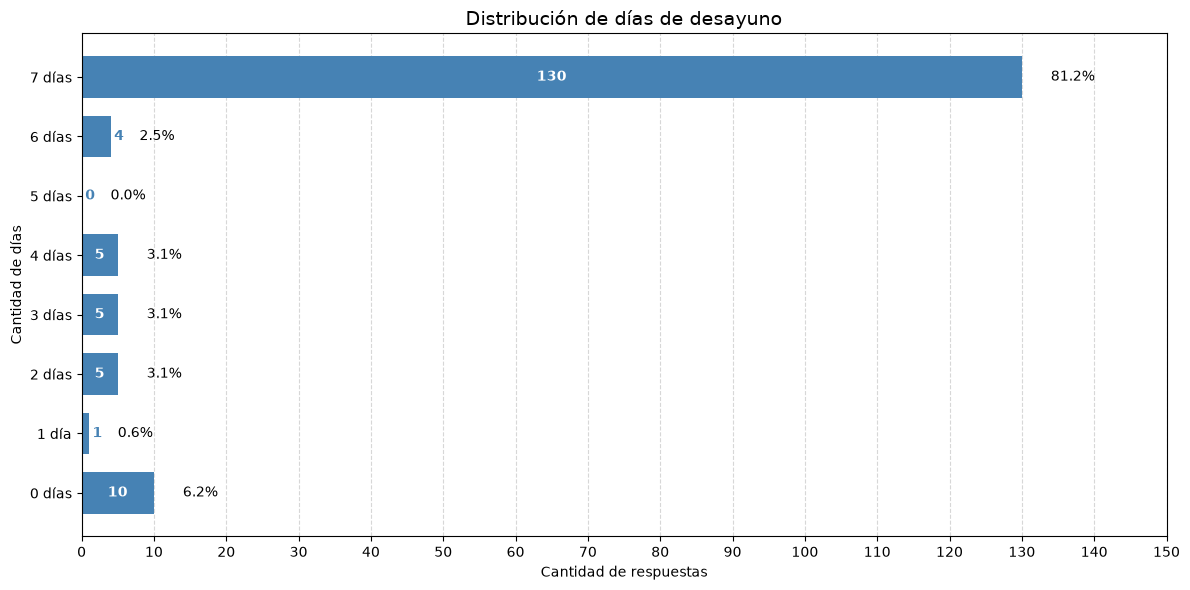

In [78]:
import matplotlib.pyplot as plt

cantidades = df_2_1_count.squeeze()
porcentajes = cantidades / cantidades.sum() * 100

fig, ax = plt.subplots(figsize=(12, 6))

color_barra = 'steelblue'

# Crear barras utilizando cantidades absolutas
barras = ax.barh(
    range(len(cantidades)),
    cantidades.values,
    color=color_barra,
    height=0.7
)

# Etiquetas del eje Y
ax.set_yticks(range(len(cantidades)))
ax.set_yticklabels([
    f'{i} día' if int(i) == 1 else f'{i} días'
    for i in cantidades.index
])

# Cantidades dentro de las barras y porcentajes a la derecha
for barra, cantidad, porcentaje in zip(
    barras, cantidades.values, porcentajes.values
):
    x = barra.get_width()
    y = barra.get_y() + barra.get_height() / 2

    # Cantidad dentro de la barra si hay espacio
    if x >= 5:
        ax.text(
            x / 2, y, str(int(cantidad)),
            ha='center', va='center',
            color='white', fontweight='bold'
        )
    else:
        ax.text(
            x + 0.5, y, str(int(cantidad)),
            ha='left', va='center',
            color=color_barra, fontweight='bold'
        )

    # Porcentaje a la derecha de la barra
    ax.text(
        x + 4, y,
        f'{porcentaje:.1f}%',
        ha='left', va='center'
    )

# Títulos
ax.set_title('Distribución de días de desayuno', fontsize=14)
ax.set_xlabel('Cantidad de respuestas')
ax.set_ylabel('Cantidad de días')

# Escala del eje X
ax.set_xlim(0, 150)
ax.set_xticks(range(0, 151, 10))

# Cuadrícula
ax.grid(axis='x', linestyle='--', alpha=0.5)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()